# Solar filament segmentation: the full pipeline

Kaggle [filament-segmentation-2026](https://www.kaggle.com/competitions/filament-segmentation-2026):
instance segmentation of solar filaments on 2048×2048 GONG H-alpha images, scored with
Panoptic Quality (PQ) per annotator record.

This notebook runs the final pipeline `v4__unet_r34_v2_bce_x2` end to end:

1. **Data**: the competition images, soft multi-annotator targets, the ground truth in the
   official evaluation format, and a 5-fold split grouped by physical image.
2. **Preprocessing**: each image becomes two input channels, `raw` and `flat`.
3. **Model**: two U-Nets (ResNet-34 encoder) trained with seeds 42 and 43, 5 folds each, so 10 networks.
   Set `TRAIN = True` to train them here (about 10 GPU hours per seed). Otherwise the trained
   weights, which are stored in this repository as the assets of its GitHub release
   [`weights-v1`](https://github.com/sergkuzn/kaggle-solar-segmentation-2026-public/releases/tag/weights-v1), are downloaded and nothing is retrained.
4. **Inference**: each seed's 5 fold models with 8-way (D4) test-time augmentation give a
   probability map, and the two seeds' maps are averaged.
5. **Post-processing**: connected components of the map become candidate filaments. A LightGBM
   scorer predicts each candidate's IoU with a ground-truth filament and keeps those above τ.
   The kept masks never overlap.
6. **Evaluation**: PQ with the official matching rule on training images the networks never saw,
   the IoU / Dice distributions and one-to-many / many-to-one relations the judges score, and
   the inference time per image.
7. **Visualisation** of predictions on test and training images.

All the code lives in the `filseg` package of this repository (`src/filseg`). The notebook
calls its stages in order, the same ones the `filseg` CLI runs. A GPU is strongly recommended:
on a CPU, inference takes about 4–5 minutes per image per seed.

Inference ran with `bfloat16` mixed precision on one NVIDIA L4 GPU (24 GB). Inference on the
180 test images (80 forward passes per image: 10 models × 8 views) takes about 21 minutes (measured in section 6).
To reproduce the maps exactly, a GPU with native bfloat16 support and the pinned package versions 
must be used. In case of using a GPU without `bfloat16` support, it is expected to run several times slower and the outputs will be slightly different.

## 0. Settings and setup

In [1]:
REPO = "sergkuzn/kaggle-solar-segmentation-2026-public"  # the public GitHub repo with the code
WEIGHTS_TAG = "weights-v1"  # its GitHub release that stores the trained weights
TRAIN = False  # True: train all 10 networks and refit the post-processing; False: download weights
EVAL_PER_FOLD = 20  # held-out training images per fold to evaluate on (0 skips the evaluation)

The cell below finds the repository, or clones it into `filseg-repo/` when the notebook runs
elsewhere (e.g. on Kaggle, with internet enabled; an existing clone is reused). It then installs
only the packages that are missing, at the versions pinned in `requirements.txt`. A preinstalled
torch (Kaggle, Colab) is kept as it is: replacing it could break its CUDA build. Finally it
prints the environment: Python, the device, and each key package's version next to its pin.
Preinstalled versions that differ from the pins can change the probability maps very slightly.

In [2]:
import importlib
import importlib.metadata
import importlib.util
import os
import platform
import subprocess
import sys
from pathlib import Path

root = Path.cwd()
if (root.parent / "pyproject.toml").exists():  # opened from notebooks/
    root = root.parent
if not (root / "src" / "filseg").exists():  # not inside the repository: use or make a clone
    clone = Path("filseg-repo").resolve()
    if not (clone / "src" / "filseg").exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", f"https://github.com/{REPO}.git", str(clone)],
            check=True,
        )
    root = clone
os.chdir(root)
sys.path.insert(0, str(root / "src"))

NEEDED = {  # import name -> package name
    "torch": "torch",
    "segmentation_models_pytorch": "segmentation-models-pytorch",
    "timm": "timm",
    "lightgbm": "lightgbm",
    "pycocotools": "pycocotools",
    "cv2": "opencv-python-headless",
    "pydantic": "pydantic",
    "yaml": "pyyaml",
    "rich": "rich",
    "typer": "typer",
    "scipy": "scipy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "tqdm": "tqdm",
}
pins = {}
for line in Path("requirements.txt").read_text().splitlines():
    name, sep, version = line.split(";")[0].strip().partition("==")
    if sep:
        pins[name.lower()] = version
missing = [pkg for module, pkg in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    specs = [f"{p}=={pins[p]}" if p in pins else p for p in missing]
    print("installing", specs)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *specs], check=True)
    importlib.invalidate_caches()


def installed_version(module: str, package: str) -> str:
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:  # e.g. cv2 from opencv-python
        return str(getattr(importlib.import_module(module), "__version__", "?"))


import torch  # noqa: E402

device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
print("repository:", root)
print(f"Python {platform.python_version()} on {platform.platform()}; device: {device_name}")
print(f"{'package':30} {'installed':>14} {'pinned':>14}")
for module, pkg in {**NEEDED, "numpy": "numpy", "torchvision": "torchvision"}.items():
    have, pin = installed_version(module, pkg).split("+")[0], pins.get(pkg, "-")
    a, b = have.split("."), pin.split(".")  # cv2: 3 of the 4 PyPI parts
    flag = "" if a[: len(b)] == b[: len(a)] else "  <- differs"
    print(f"{pkg:30} {have:>14} {pin:>14}{flag}")

repository: /home/sergei/repo
Python 3.12.3 on Linux-7.0.0-1017-gcp-x86_64-with-glibc2.39; device: NVIDIA L4
package                             installed         pinned
torch                                  2.14.1         2.14.1
segmentation-models-pytorch             0.5.0          0.5.0
timm                                   1.0.30         1.0.30
lightgbm                                4.7.0          4.7.0
pycocotools                            2.0.11         2.0.11
opencv-python-headless               5.0.0.93       5.0.0.93
pydantic                               2.13.5         2.13.5
pyyaml                                  6.0.3          6.0.3
rich                                   15.0.0         15.0.0
typer                                  0.27.2         0.27.2
scipy                                  1.18.1         1.18.1
pandas                                  3.0.6          3.0.6
matplotlib                             3.11.2         3.11.2
tqdm                                 

In [3]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display  # noqa: A004 (IPython's display)
from tqdm.auto import tqdm

from filseg.config import load_config
from filseg.infra.paths import get_paths

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
paths = get_paths()  # data/ and outputs/ in the repo root (FILSEG_DATA_DIR / FILSEG_OUTPUT_DIR)
WORKERS = os.cpu_count() or 1
print("device:", "cuda" if torch.cuda.is_available() else "cpu", "| workers:", WORKERS)

MEMBERS = ["v2__unet_r34_v2_bce", "v4__unet_r34_v2_bce_s43"]  # seed 42, seed 43
FINAL = "v4__unet_r34_v2_bce_x2"  # their blend + the LightGBM scorer
final = load_config(Path(f"configs/{FINAL}.yaml"))
assert final.blend == MEMBERS

device: cuda | workers: 8


## 1. Data

On Kaggle the competition data is mounted under `/kaggle/input` and linked into `data/raw`.
Elsewhere it is downloaded with the Kaggle CLI, which needs an API token in
`~/.kaggle/access_token` (or `KAGGLE_API_TOKEN`) and the competition rules accepted.

`prepare` then builds the per-image soft targets: each pixel's target is the fraction of
annotators who marked it, plus a thin "spine" target used by an auxiliary head. It also
writes the ground-truth table in the official format and the 5-fold split. The split is
grouped by physical image, so the annotator records of one image never fall into different folds.

In [4]:
from filseg.stages import data

if not paths.train_images.is_dir():
    mounted = [
        p
        for pattern in ("*/MAGFiLO_1.0_Kaggle_2026", "*/*/MAGFiLO_1.0_Kaggle_2026")
        for p in Path("/kaggle/input").glob(pattern)
    ]
    if mounted:
        paths.raw.mkdir(parents=True, exist_ok=True)
        paths.dataset.symlink_to(mounted[0], target_is_directory=True)
    else:
        data.download(paths, force=False)
        data.extract(paths)
data.prepare(paths, n_folds=5, seed=42, spine_thickness=5, workers=WORKERS, force=False)

folds = pd.read_csv(paths.folds_csv)
gt = pd.read_csv(paths.gt_csv)
n_test = len(list(paths.test_images.glob("*.jpeg")))
print(f"{len(folds)} training images, {n_test} test images, {len(gt)} annotated filaments")
print("images per fold:", folds.fold.value_counts().sort_index().to_dict())


  0%|          | 0.00/671M [00:00<?, ?B/s]
  0%|          | 1.00M/671M [00:00<01:15, 9.27MB/s]


  2%|▏         | 11.0M/671M [00:00<00:11, 60.7MB/s]
  3%|▎         | 23.0M/671M [00:00<00:10, 67.2MB/s]


  5%|▌         | 35.0M/671M [00:00<00:07, 84.9MB/s]
  7%|▋         | 44.0M/671M [00:00<00:09, 70.6MB/s]


  8%|▊         | 52.0M/671M [00:00<00:09, 71.3MB/s]
  9%|▉         | 60.0M/671M [00:00<00:08, 73.5MB/s]


 11%|█         | 75.0M/671M [00:01<00:06, 90.4MB/s]
 13%|█▎        | 89.0M/671M [00:01<00:05, 105MB/s] 


 15%|█▌        | 103M/671M [00:01<00:05, 116MB/s] 
 17%|█▋        | 115M/671M [00:01<00:04, 118MB/s]

... (164 outputs left out)


targets: 100%|█████████▉| 706/707 [00:59<00:00, 11.50it/s]


targets: 100%|██████████| 707/707 [00:59<00:00, 11.82it/s]

INFO filseg.stages.data: folds: {0: 142, 1: 142, 2: 141, 3: 141, 4: 141}


707 training images, 180 test images, 8199 annotated filaments
images per fold: {0: 142, 1: 142, 2: 141, 3: 141, 4: 141}


## 2. Preprocessing

First the solar disk is located. The image then becomes two channels: `raw`, the intensity
standardised over the disk, and `flat`, the intensity minus a disk-aware 48 px Gaussian background.
`flat` removes limb darkening and large-scale brightness changes, so the thin dark filaments
stand out. At inference the network sees the centred 1888×1888 crop that holds the disk.

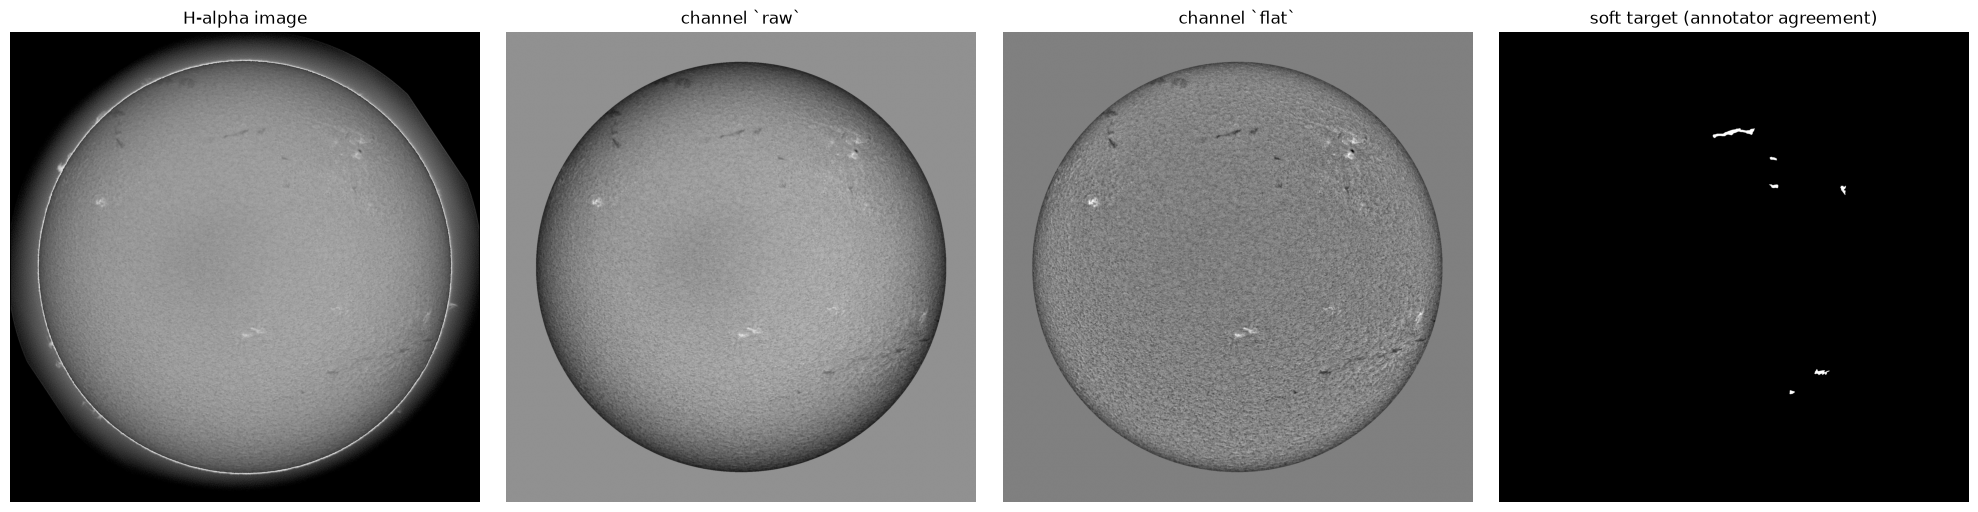

In [5]:
from filseg.imaging import read_gray
from filseg.preprocess import build_channels

stem = folds.stem.iloc[0]
img = read_gray(paths.train_images / f"{stem}.jpeg")
member_cfg = load_config(Path(f"configs/{MEMBERS[0]}.yaml"))
channels = build_channels(img, member_cfg.data.channels)
soft = read_gray(paths.targets / f"{stem}_soft.png")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
panels = [
    (img, "H-alpha image"),
    (channels[0], "channel `raw`"),
    (channels[1], "channel `flat`"),
    (soft, "soft target (annotator agreement)"),
]
for ax, (im, title) in zip(axes, panels, strict=True):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Model

Each member is a U-Net with an ImageNet-pretrained ResNet-34 encoder
(`segmentation_models_pytorch`) and two output heads: the filament probability and the spine.
It is trained with BCE against the soft targets (plus 0.3 × spine BCE) on random
768×768 windows, 70% of them centred on a filament, with dihedral flips and gain/offset jitter.
Training uses AdamW (lr 3·10⁻⁴, weight decay 10⁻², 1 warm-up epoch, cosine decay) for 80 epochs of 200 steps,
batch 8, mixed precision. The checkpoint with the best validation PQ is kept for each fold.
The two members differ only in the random seed. The full settings are in `configs/<member>.yaml`.

- `TRAIN = True`: train the 5 folds of both members. Training writes each image's
  out-of-fold (OOF) probability map from the model that did not see it. Those maps are then
  used to fit the post-processing (section 5).
- `TRAIN = False`: download the trained weights. They are stored in this repository as the
  assets of its GitHub release [`weights-v1`](https://github.com/sergkuzn/kaggle-solar-segmentation-2026-public/releases/tag/weights-v1) (about 1 GB): the best checkpoint of
  each of the 10 folds, the fitted LightGBM scorer, the tuned post-processing parameters and a
  `manifest.json`. Every file's SHA-256 is checked against the manifest. Nothing is retrained,
  and the predictions below are made with exactly the weights behind the submitted results.

In [6]:
if TRAIN:
    from filseg.stages import train

    for name in MEMBERS:
        cfg = load_config(Path(f"configs/{name}.yaml"))
        train.run(cfg, paths, folds=None)  # 5 folds; writes checkpoints and OOF maps
else:
    from filseg.infra import release

    release.fetch(release.release_url(REPO, WEIGHTS_TAG), paths)

for name in MEMBERS:
    print(name, [paths.experiment(name).model(k).name for k in range(5)])


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:   0%|          | 0.00/97.9M [00:00<?, ?B/s]


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:   1%|          | 1.05M/97.9M [00:00<00:17, 5.59MB/s]


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:  15%|█▍        | 14.7M/97.9M [00:00<00:01, 60.1MB/s]


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:  24%|██▎       | 23.1M/97.9M [00:00<00:01, 42.5MB/s]


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:  34%|███▍      | 33.6M/97.9M [00:00<00:01, 56.0MB/s]


v2__unet_r34_v2_bce--folds--fold0--model_70.pt:  48%|████▊     | 47.2M/97.9M [00:00<00:00, 76.2MB/s]

... (139 outputs left out)


v4__unet_r34_v2_bce_x2--scorer--model_b4_h0.txt: 100%|██████████| 306k/306k [00:00<00:00, 1.60MB/s]


INFO filseg.infra.release: downloaded v4__unet_r34_v2_bce_x2/scorer/model_b4_h0.txt


INFO filseg.infra.release: fetched 22 files of v4__unet_r34_v2_bce_x2 into /home/sergei/repo/outputs


v2__unet_r34_v2_bce ['model_70.pt', 'model_64.pt', 'model_36.pt', 'model_58.pt', 'model_68.pt']
v4__unet_r34_v2_bce_s43 ['model_52.pt', 'model_66.pt', 'model_68.pt', 'model_52.pt', 'model_74.pt']


## 4. Inference

For each member, `write-maps` runs the 5 fold models with D4 test-time augmentation (the
8 flips and rotations) on every test image and averages the 40 predictions into one
probability map. `blend` then averages the two members' maps.

For the evaluation in section 6 (when `TRAIN = False`), `write-maps` also predicts the first
`EVAL_PER_FOLD` training images of every fold, each with the model of the fold that held it out.
With `TRAIN = True` the OOF maps of all training images already exist.

The test-set inference is timed for the computational-efficiency summary in section 6.

In [7]:
import time

from filseg.stages import blend, write_maps

# inference reads each image once: do not cache the preprocessed inputs
infer_overrides = ["data.cache='off'"]
evaluate_here = not TRAIN and EVAL_PER_FOLD > 0
infer_seconds = {}  # member -> wall time of its test maps (5 folds x 8 TTA views)
for name in MEMBERS:
    overrides = infer_overrides + ([f"train.val_limit={EVAL_PER_FOLD}"] if evaluate_here else [])
    cfg = load_config(Path(f"configs/{name}.yaml"), overrides)
    start = time.perf_counter()
    write_maps.run(cfg, paths, split=write_maps.Split.TEST)
    infer_seconds[name] = time.perf_counter() - start
    if evaluate_here:
        write_maps.run(cfg, paths, split=write_maps.Split.OOF)

have_oof = all(paths.experiment(name).oof.is_dir() for name in MEMBERS)
start = time.perf_counter()
blend.run(final, paths, workers=WORKERS, split=blend.Split.ALL if have_oof else blend.Split.TEST)
blend_seconds = time.perf_counter() - start

INFO filseg.stages.write_maps: 180 test maps, 5 models (tta=d4)



prob maps -> test_probs:   0%|          | 0/180 [00:00<?, ?it/s]


prob maps -> test_probs:   1%|          | 1/180 [00:03<10:06,  3.39s/it]


prob maps -> test_probs:   1%|          | 2/180 [00:06<09:41,  3.27s/it]


prob maps -> test_probs:   2%|▏         | 3/180 [00:09<09:32,  3.24s/it]


prob maps -> test_probs:   2%|▏         | 4/180 [00:12<09:27,  3.22s/it]

... (599 outputs left out)


test_probs:  83%|████████▎ | 149/180 [00:03<00:00, 52.00it/s]


test_probs: 100%|██████████| 180/180 [00:03<00:00, 54.76it/s]


INFO filseg.stages.common: wrote /home/sergei/repo/outputs/v4__unet_r34_v2_bce_x2/blend.json


INFO filseg.stages.blend: blended ['v2__unet_r34_v2_bce', 'v4__unet_r34_v2_bce_s43'] -> /home/sergei/repo/outputs/v4__unet_r34_v2_bce_x2: {'oof': 100, 'test_probs': 180}


## 5. Post-processing and submission

One map pixel per image pixel is not yet an answer: PQ needs separate filament instances, and
every false positive costs as much as a missed filament. Post-processing therefore works per
candidate:

1. **Candidates**: connected components of the blended map at threshold 0.35, after a morphological
   closing (radius 2); components under 20 px are dropped.
2. **Scoring**: a LightGBM regressor (5 bags) predicts from 22 features of each candidate its expected IoU
   with a ground-truth filament. The features cover probability quantiles, shape, intensity contrast,
   neighbours, and how the blob grows at lower thresholds.
3. **Selection**: keep candidates with predicted IoU above τ = 0.23. In theory a match is worth
   keeping when IoU > PQ/2, and τ ≈ 0.23 is close to that.

With `TRAIN = True` the threshold and closing radius are tuned on the OOF maps (`tune`). The
scorer is then fitted on the OOF candidates (`fit-scorer`), and its PQ is measured with nested
cross-fitting: each fold is scored by a model fitted on the other four. `predict`
applies the scorer to the blended test maps and writes `submission.csv`, after checking its format,
that every mask decodes, and that no two masks overlap.

In [8]:
from filseg.stages import predict

if TRAIN:
    from filseg.stages import fit_scorer, tune

    tune.run(final, paths, workers=WORKERS)
    fit_scorer.run(final, paths, workers=WORKERS)

start = time.perf_counter()
predict.run(final, paths)
post_seconds = time.perf_counter() - start
exp = paths.experiment(FINAL)
submission = pd.read_csv(exp.submission)
n_images = submission.filament_id.str.rsplit("_", n=1).str[0].nunique()
print(f"{len(submission)} filaments on {n_images} of {n_test} test images")
submission.head()


test (flat):   0%|          | 0/180 [00:00<?, ?it/s]


test (flat):   1%|          | 1/180 [00:00<01:04,  2.78it/s]


test (flat):   1%|          | 2/180 [00:00<01:00,  2.95it/s]


test (flat):   2%|▏         | 3/180 [00:01<01:00,  2.91it/s]


test (flat):   2%|▏         | 4/180 [00:01<01:03,  2.76it/s]


test (flat):   3%|▎         | 5/180 [00:01<01:03,  2.73it/s]

... (177 outputs left out)

{
    'rows': 1101,
    'images_with_predictions': 177,
    'images_expected': 180,
    'mean_instances_per_image': 6.220338983050848
}

INFO filseg.stages.predict: wrote /home/sergei/repo/outputs/v4__unet_r34_v2_bce_x2/submission.csv


1101 filaments on 177 of 180 test images


,filament_id,segmentation_rle
0,20110120105534Ch_1,l_Vi22mo13O0O2O1fPNKfn15ZQNLen15YQNLgn14YQNLhn...
1,20110120105534Ch_2,ajRP22mo1100O100O100N10N201O10O010O1N3N0000001...
2,20110130110334Ch_1,b_Pe2;co13O2N5K1001NmPNAgn1>WQNDin1<TQNFmn1f01...
3,20110214175414Mh_1,Z]d[25go15N2M3N2H701N101oNWOhRNk0Um1XOjRNh0Um1...
4,20110214175414Mh_2,_^^d23lo12O1O001O0O100010O01O1O0000000O10O01O1...


## 6. Evaluation

The test labels are hidden, so the score is measured on training images, using the official
matching rule (`filseg.competition.metric`, checked against the organizers' self-evaluation
notebook). Each image's map comes from networks that never saw it. The selection step above is
applied unchanged.

Caveat: two things make this number somewhat optimistic. The released scorer was fitted on the
OOF candidates of *all* training images, including these ones. And each fold's checkpoint is the
epoch with the best validation PQ on that fold's held-out images, these ones included. The least
biased estimate is the nested cross-fit PQ: **0.4643** for this pipeline (printed below when
`TRAIN = True`); it shares the checkpoint caveat, but not the scorer one. For scale, two human annotators agree with each other at PQ ≈ 0.34 on this data.

In [9]:
import json

from filseg.competition.metric import evaluate_subset
from filseg.competition.submission import build_submission
from filseg.imaging import read_prob
from filseg.postprocess.scorer import Scorer
from filseg.stages.common import print_pq

scorer_files = exp.scorer
scorer = Scorer.load(scorer_files.model, scorer_files.params)
eval_stems = sorted(p.stem for p in exp.oof.glob("*.png")) if exp.oof.is_dir() else []
if eval_stems:
    preds = [
        (
            s,
            scorer.extract(
                read_prob(exp.oof / f"{s}.png"), read_gray(paths.train_images / f"{s}.jpeg")
            ),
        )
        for s in tqdm(eval_stems, desc="scoring held-out images")
    ]
    oof_pred = build_submission(preds)
    oof_pred.to_csv(exp.root / "eval_predictions.csv", index=False)
    result = evaluate_subset(gt, oof_pred, set(eval_stems))
    print_pq(f"{len(eval_stems)} held-out training images", result)
if scorer_files.crossfit.exists():
    print("nested cross-fit (honest) PQ:", json.loads(scorer_files.crossfit.read_text()))

scoring held-out images:   0%|          | 0/100 [00:00<?, ?it/s]

              100 held-out training images              
┏━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━┳━━━━━┳━━━━━┳━━━━━━━━━┓
┃     PQ ┃     SQ ┃     RQ ┃  TP ┃  FP ┃  FN ┃ records ┃
┡━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━╇━━━━━╇━━━━━╇━━━━━━━━━┩
│ 0.4645 │ 0.6817 │ 0.6814 │ 786 │ 275 │ 460 │     173 │
└────────┴────────┴────────┴─────┴─────┴─────┴─────────┘

### IoU and Dice distributions, one-to-many and many-to-one relations

Besides PQ, the judges score the distributions of IoU and Dice and the one-to-many /
many-to-one relations between the ground truth and the predictions. Like PQ, they are counted
per annotator record: an image with three annotators contributes three times.

- **IoU and Dice** of every overlapping (GT, prediction) pair. Pairs with IoU > 0.5
  (equivalently Dice > 2/3) are the true positives PQ counts. The pairs below that are partial
  overlaps: boundary disagreement, or a filament split into pieces or merged with another.
- **Relations**: for each GT filament, the number of predictions it overlaps (0 = missed,
  2 or more = one-to-many, a split), and for each prediction, the number of GT filaments it
  overlaps (0 = nothing annotated under it, 2 or more = many-to-one, a merge).

The tables are saved next to the predictions (`eval_pairs.csv`, `eval_relations.csv`).

991 overlapping pairs, 786 of them true positives (IoU > 0.5)
tp            False    True 
iou  count  205.000  786.000
     mean     0.328    0.682
     std      0.135    0.087
     min      0.035    0.502
     25%      0.228    0.613
     50%      0.360    0.684
     75%      0.456    0.749
     max      0.500    0.884
dice count  205.000  786.000
     mean     0.478    0.808
     std      0.164    0.062
     min      0.067    0.669
     25%      0.371    0.760
     50%      0.530    0.812
     75%      0.627    0.856
     max      0.667    0.938
          gt_filaments  predictions  gt_filaments share  predictions share
partners                                                                  
0                  288          102               0.231              0.096
1                  926          929               0.743              0.876
2                   31           28               0.025              0.026
3+                   1            2               0.001              0

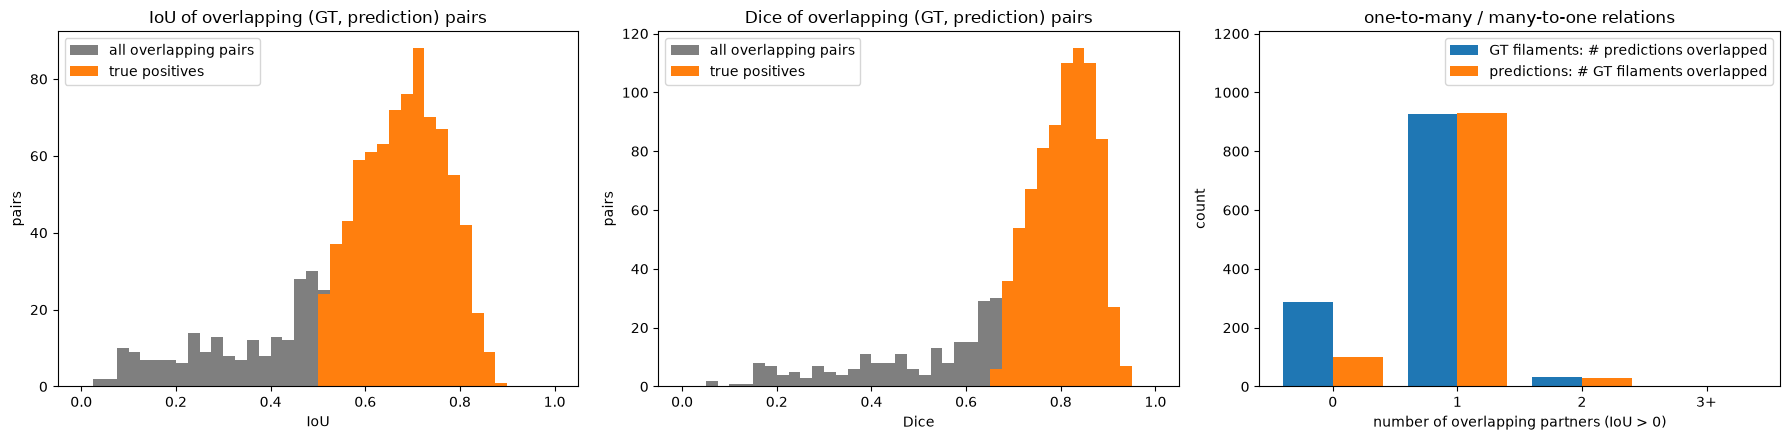

In [10]:
if eval_stems:
    pairs = result.pairs()
    relations = result.relations()
    pairs.to_csv(exp.root / "eval_pairs.csv", index=False)
    relations.to_csv(exp.root / "eval_relations.csv")

    tp_pairs = pairs[pairs.tp]
    print(f"{len(pairs)} overlapping pairs, {len(tp_pairs)} of them true positives (IoU > 0.5)")
    print(pairs.groupby("tp")[["iou", "dice"]].describe().round(3).T)

    # 3 or more partners in one bar
    rel = relations.groupby(np.minimum(relations.index, 3)).sum()
    rel.index = [str(n) if n < 3 else "3+" for n in rel.index]
    shares = (rel / rel.sum()).round(3).add_suffix(" share")
    print(pd.concat([rel, shares], axis=1).rename_axis("partners"))

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    bins = np.linspace(0, 1, 41)
    for ax, col, label in zip(axes[:2], ("iou", "dice"), ("IoU", "Dice"), strict=True):
        ax.hist(pairs[col], bins=bins, color="tab:gray", label="all overlapping pairs")
        ax.hist(tp_pairs[col], bins=bins, color="tab:orange", label="true positives")
        ax.set_xlabel(label)
        ax.set_ylabel("pairs")
        ax.set_title(f"{label} of overlapping (GT, prediction) pairs")
        ax.legend()
    x = np.arange(len(rel))
    axes[2].bar(x - 0.2, rel.gt_filaments, 0.4, label="GT filaments: # predictions overlapped")
    axes[2].bar(x + 0.2, rel.predictions, 0.4, label="predictions: # GT filaments overlapped")
    axes[2].set_xticks(x, rel.index)
    axes[2].set_xlabel("number of overlapping partners (IoU > 0)")
    axes[2].set_ylabel("count")
    axes[2].set_title("one-to-many / many-to-one relations")
    axes[2].set_ylim(top=1.3 * rel.to_numpy().max())  # room for the legend
    axes[2].legend()
    plt.tight_layout()
    plt.show()

### Computational cost

Wall time of the test-set inference measured above: the networks (reading and preprocessing
each image, 2 seeds × 5 folds × 8 TTA views), the blend of the two seeds' maps, and the
post-processing (candidates, scorer, submission checks).

In [11]:
net = sum(infer_seconds.values())
print(f"device: {device_name}; {n_test} test images")
print(f"networks:        {net / n_test:7.2f} s per image ({net / 60:.1f} min in total)")
print(f"blend:           {blend_seconds / n_test:7.2f} s per image (includes the OOF maps if any)")
print(f"post-processing: {post_seconds / n_test:7.2f} s per image")

device: NVIDIA L4; 180 test images
networks:           6.59 s per image (19.8 min in total)
blend:              0.03 s per image (includes the OOF maps if any)
post-processing:    0.36 s per image


## 7. Visualisation

Orange: predicted filaments. On training images, the ground truth of each annotator is drawn
in its own colour. Annotators often disagree about whether faint filaments exist and where their
boundaries are; this disagreement is why human-vs-human PQ is only 0.34.

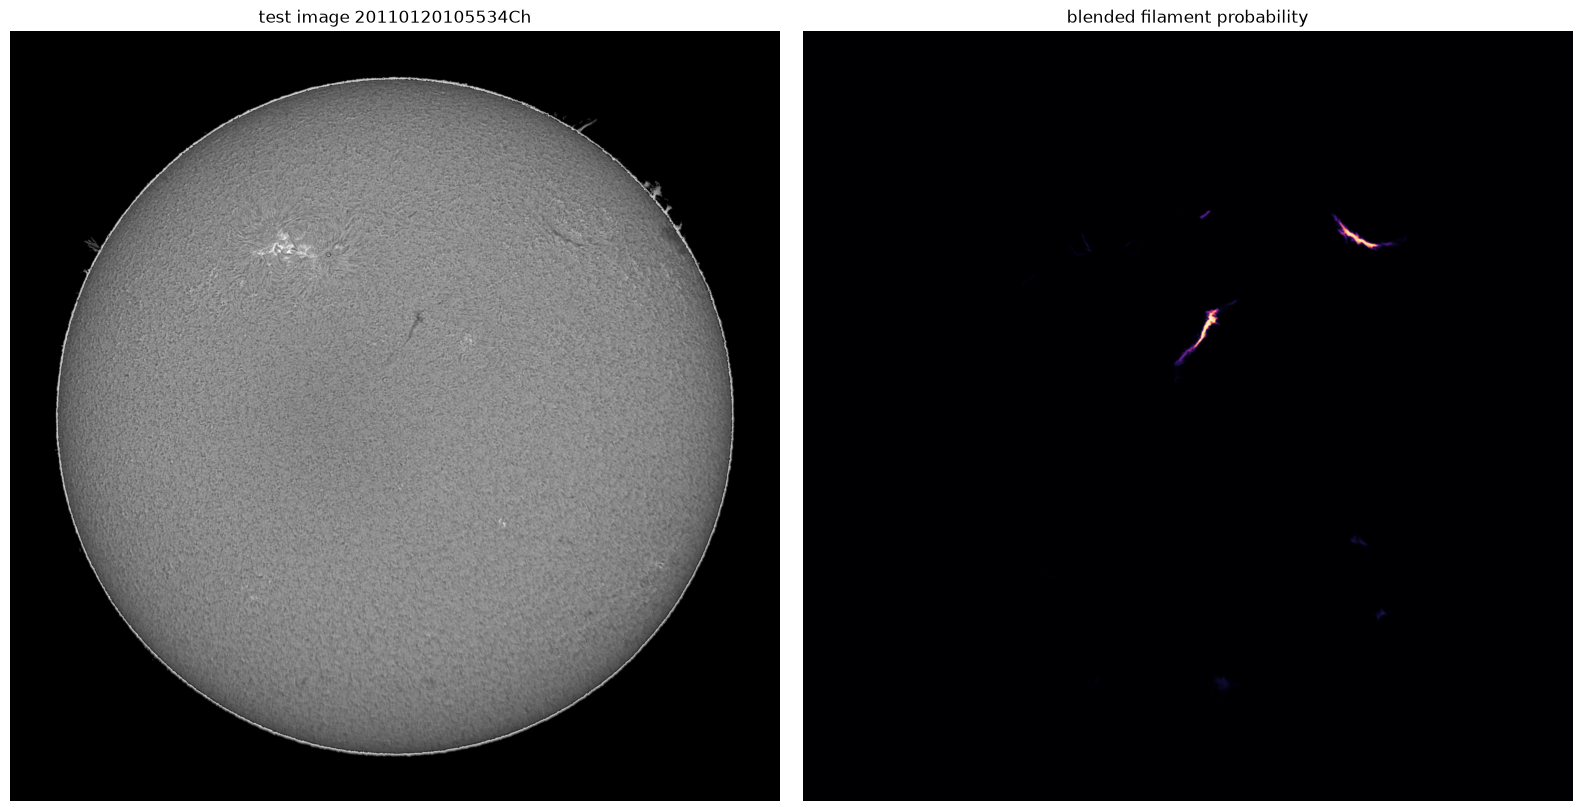

In [12]:
test_stem = sorted(p.stem for p in paths.test_images.glob("*.jpeg"))[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(read_gray(paths.test_images / f"{test_stem}.jpeg"), cmap="gray")
axes[0].set_title(f"test image {test_stem}")
axes[1].imshow(read_prob(exp.test_probs / f"{test_stem}.png"), cmap="magma", vmin=0, vmax=1)
axes[1].set_title("blended filament probability")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

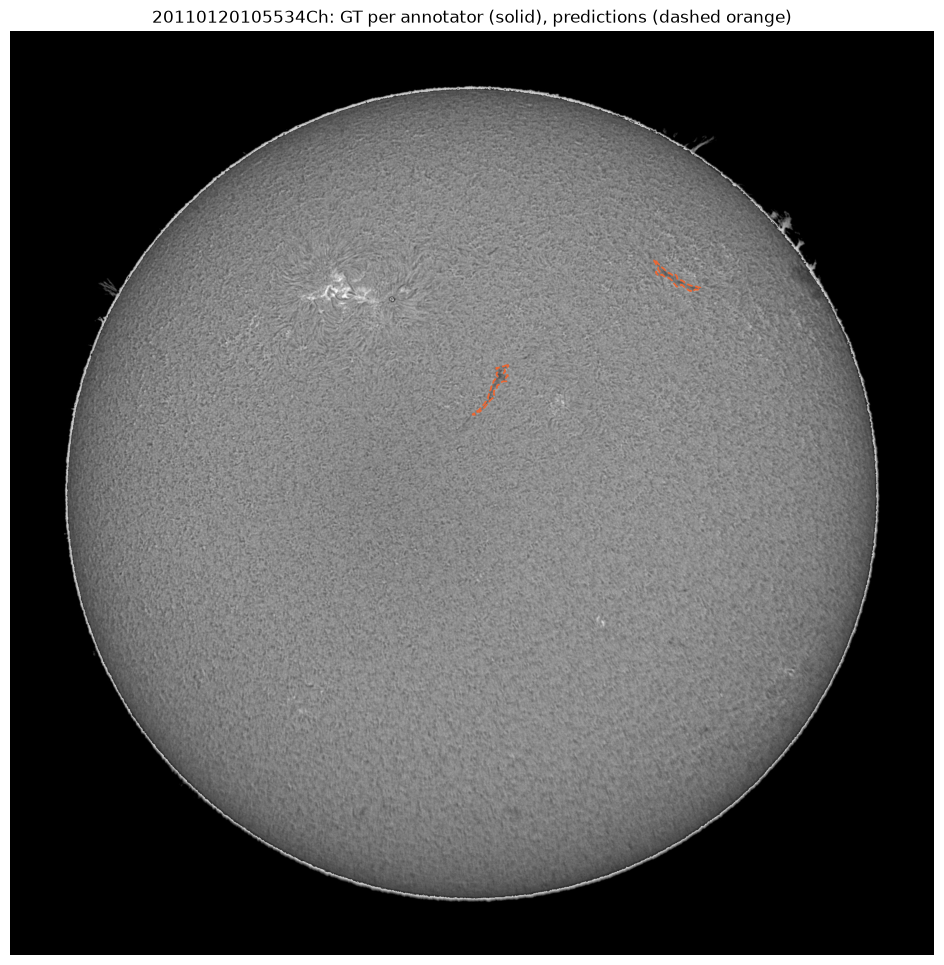

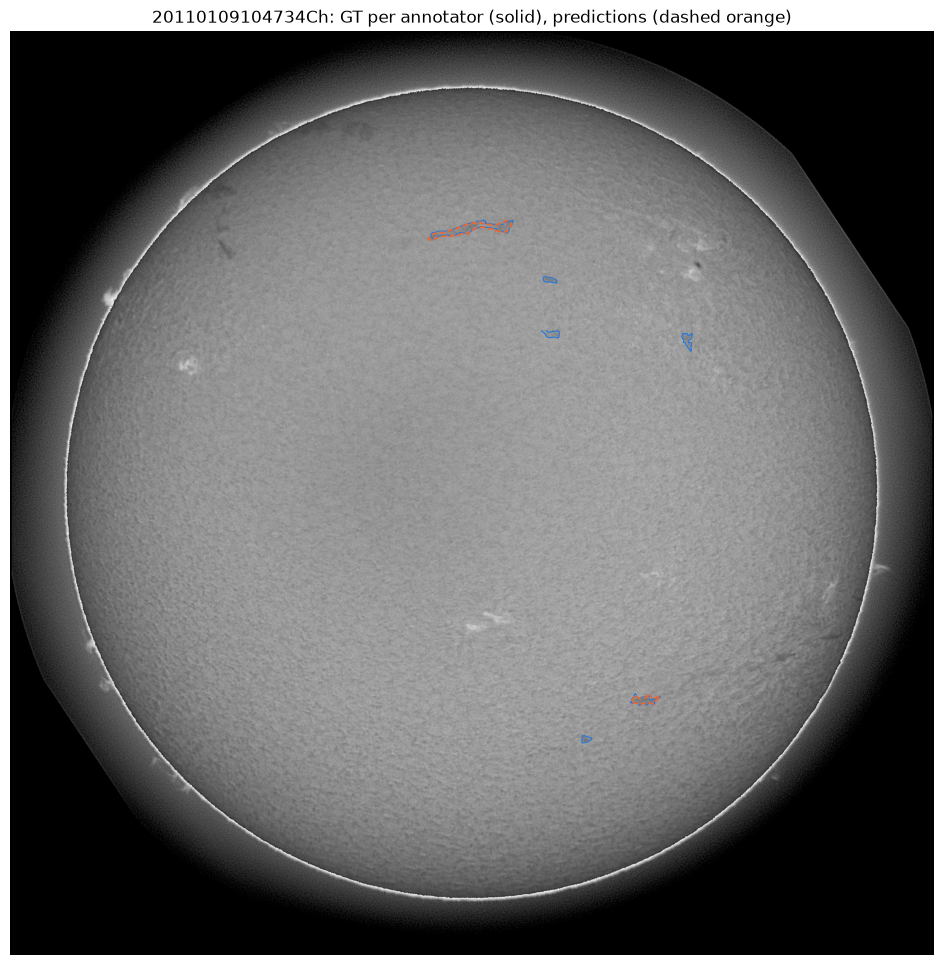

In [13]:
from filseg.stages.viz import render_overlay  # switches matplotlib to Agg: keep it last

figures = exp.root / "figures"
shown = [(test_stem, exp.submission)]
if eval_stems:
    shown.append((eval_stems[0], exp.root / "eval_predictions.csv"))
for s, predictions in shown:
    render_overlay(paths, s, predictions, figures / f"{s}.png")
    display(Image(filename=figures / f"{s}.png", width=800))